# Colas de prioridad y árbol de expansión mínima
**Diseño y Desarrollo de Algoritmos – 2026-2**

Se implementa una cola de prioridad con un Max-Heap y el algoritmo de Kruskal para conectar seis dispositivos con la menor longitud total de cable. No se utiliza `heapq` ni funciones que calculen directamente el MST.

## Punto 1. Cola de prioridad
Cada tarea se representa mediante una tupla `(código, tarea, prioridad)`. La raíz del Max-Heap contiene la tarea de mayor prioridad. Se construye el heap de abajo hacia arriba, aplicando MAX-HEAPIFY a los nodos internos.

In [1]:
import math
import matplotlib.pyplot as plt

heap = [
    ("T01", "Configurar servidor", 6),
    ("T02", "Reparar sensor", 10),
    ("T03", "Actualizar software", 4),
    ("T04", "Revisar cámara", 8),
    ("T05", "Generar respaldo", 3),
    ("T06", "Configurar alarma", 7)
]

def mostrar_heap(h):
    print([(t[0], t[2]) for t in h])

def max_heapify(h, i):
    n = len(h)
    while True:
        mayor = i
        izq = 2*i + 1
        der = 2*i + 2
        if izq < n and h[izq][2] > h[mayor][2]:
            mayor = izq
        if der < n and h[der][2] > h[mayor][2]:
            mayor = der
        if mayor == i:
            break
        h[i], h[mayor] = h[mayor], h[i]
        i = mayor

def build_max_heap(h):
    for i in range(len(h)//2 - 1, -1, -1):
        max_heapify(h, i)

def es_max_heap(h):
    return all(h[(i-1)//2][2] >= h[i][2] for i in range(1, len(h)))

print("Arreglo inicial:")
mostrar_heap(heap)
build_max_heap(heap)
print("Max-Heap resultante:")
mostrar_heap(heap)
assert es_max_heap(heap)

Arreglo inicial:
[('T01', 6), ('T02', 10), ('T03', 4), ('T04', 8), ('T05', 3), ('T06', 7)]
Max-Heap resultante:
[('T02', 10), ('T04', 8), ('T06', 7), ('T01', 6), ('T05', 3), ('T03', 4)]


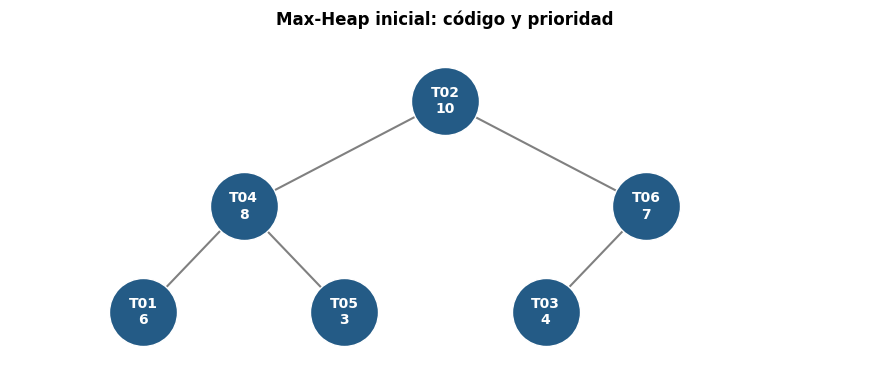

In [2]:
def dibujar_heap(h, titulo):
    fig, ax = plt.subplots(figsize=(9, 4))
    posiciones = {}
    for i in range(len(h)):
        nivel = (i+1).bit_length()-1
        lugar = i-(2**nivel-1)
        posiciones[i] = ((lugar+0.5)/2**nivel, -nivel)
    for i in range(1, len(h)):
        x1, y1 = posiciones[(i-1)//2]
        x2, y2 = posiciones[i]
        ax.plot([x1,x2], [y1,y2], color="gray", zorder=1)
    for i, tarea in enumerate(h):
        x,y = posiciones[i]
        ax.scatter(x,y,s=2400,color="#245b86",edgecolors="white",zorder=2)
        ax.text(x,y,f"{tarea[0]}\n{tarea[2]}",ha="center",va="center",color="white",weight="bold",zorder=3)
    ax.set_xlim(-0.04,1.04)
    ax.set_ylim(min(y for x,y in posiciones.values())-0.65,0.65)
    ax.set_title(titulo,weight="bold")
    ax.axis("off")
    fig.tight_layout()
    return fig

fig = dibujar_heap(heap, "Max-Heap inicial: código y prioridad")
plt.show()

## Punto 2. Procesar tareas
EXTRACT-MAX retira la raíz, mueve el último elemento a la raíz y restablece el heap. Para insertar una tarea, se agrega al final y se intercambia con su padre mientras tenga mayor prioridad.

Tarea procesada: T02 - Reparar sensor - Prioridad 10
Heap resultante:
[('T04', 8), ('T01', 6), ('T06', 7), ('T03', 4), ('T05', 3)]

Tarea procesada: T04 - Revisar cámara - Prioridad 8
Heap resultante:
[('T06', 7), ('T01', 6), ('T05', 3), ('T03', 4)]

Heap después de insertar T07:
[('T07', 12), ('T06', 7), ('T05', 3), ('T03', 4), ('T01', 6)]


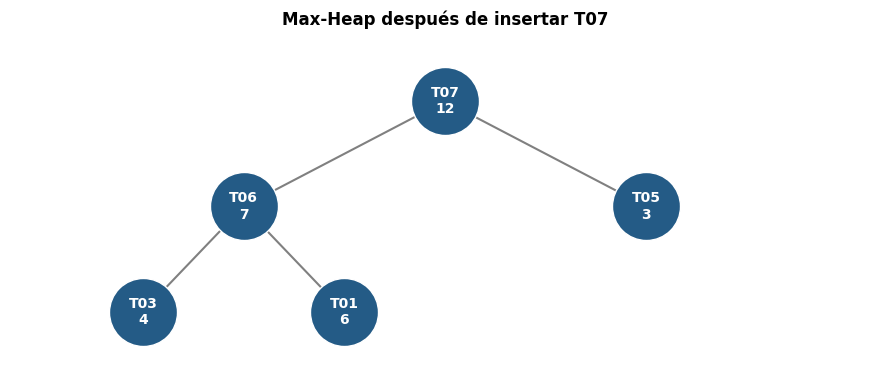

In [3]:
def extract_max(h):
    if not h:
        raise IndexError("La cola está vacía")
    maxima = h[0]
    ultimo = h.pop()
    if h:
        h[0] = ultimo
        max_heapify(h, 0)
    return maxima

def insertar(h, tarea):
    h.append(tarea)
    i = len(h)-1
    while i > 0:
        padre = (i-1)//2
        if h[padre][2] >= h[i][2]:
            break
        h[i], h[padre] = h[padre], h[i]
        i = padre

for _ in range(2):
    tarea = extract_max(heap)
    print(f"Tarea procesada: {tarea[0]} - {tarea[1]} - Prioridad {tarea[2]}")
    print("Heap resultante:")
    mostrar_heap(heap)
    assert es_max_heap(heap)
    print()

nueva = ("T07", "Falla en sistema contra incendios", 12)
insertar(heap, nueva)
print("Heap después de insertar T07:")
mostrar_heap(heap)
assert es_max_heap(heap)
fig = dibujar_heap(heap, "Max-Heap después de insertar T07")
plt.show()

## Punto 3. Dispositivos a conectar
Se representan los seis dispositivos en el plano cartesiano y se calcula la distancia euclidiana de cada pareja. Cada arista se genera una sola vez, para un total de 15 conexiones posibles.

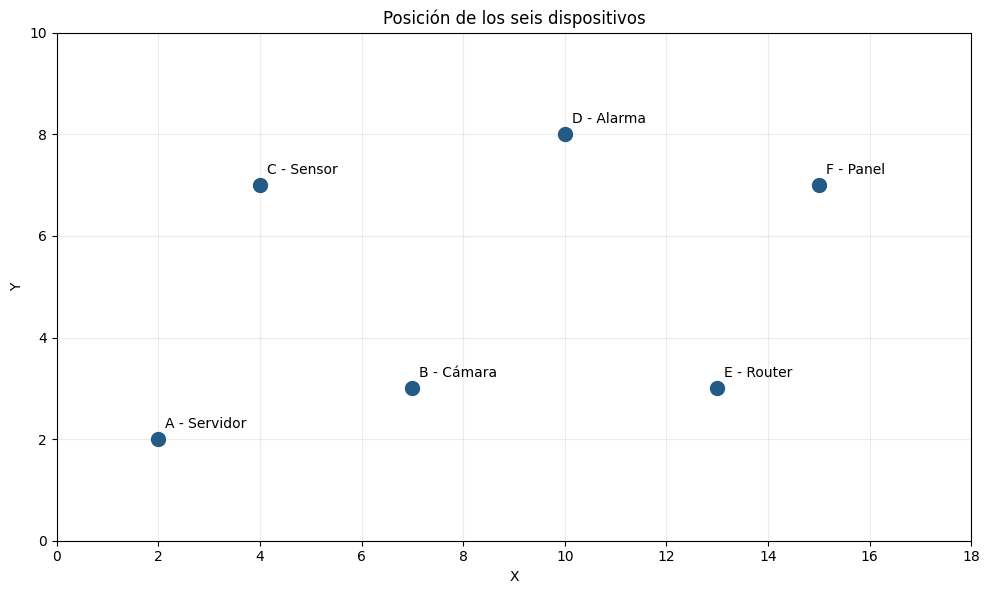

A - B: 5.10
A - C: 5.39
A - D: 10.00
A - E: 11.05
A - F: 13.93
B - C: 5.00
B - D: 5.83
B - E: 6.00
B - F: 8.94
C - D: 6.08
C - E: 9.85
C - F: 11.00
D - E: 5.83
D - F: 5.10
E - F: 4.47


In [4]:
dispositivos = {
    "A": ("Servidor", 2, 2),
    "B": ("Cámara", 7, 3),
    "C": ("Sensor", 4, 7),
    "D": ("Alarma", 10, 8),
    "E": ("Router", 13, 3),
    "F": ("Panel", 15, 7)
}

def graficar_dispositivos(ax):
    for id, (nombre, x, y) in dispositivos.items():
        ax.scatter(x,y,s=100,color="#245b86",zorder=3)
        ax.annotate(f"{id} - {nombre}",(x,y),xytext=(5,8),textcoords="offset points")
    ax.set(xlabel="X",ylabel="Y",xlim=(0,18),ylim=(0,10))
    ax.set_aspect("equal")
    ax.grid(alpha=0.25)

fig, ax = plt.subplots(figsize=(10,6))
graficar_dispositivos(ax)
ax.set_title("Posición de los seis dispositivos")
fig.tight_layout()
plt.show()

aristas = []
ids = list(dispositivos)
for i in range(len(ids)):
    for j in range(i+1,len(ids)):
        a,b = ids[i],ids[j]
        _,x1,y1 = dispositivos[a]
        _,x2,y2 = dispositivos[b]
        distancia = math.sqrt((x2-x1)**2+(y2-y1)**2)
        aristas.append((distancia,a,b))
        print(f"{a} - {b}: {distancia:.2f}")
assert len(aristas) == 15

## Punto 4. Árbol de expansión mínima (Kruskal)
Se ordenan las aristas de menor a mayor peso. Mediante conjuntos disjuntos se verifica si los extremos de una arista pertenecen a componentes diferentes. Si es así, se unen; si no, se descarta para evitar ciclos. Se detiene al seleccionar cinco conexiones. Las distancias se mantienen sin redondear hasta su presentación.

In [5]:
def kruskal(vertices, aristas):
    padre = {v:v for v in vertices}
    rango = {v:0 for v in vertices}

    def encontrar(v):
        if padre[v] != v:
            padre[v] = encontrar(padre[v])
        return padre[v]

    def unir(a,b):
        ra,rb = encontrar(a),encontrar(b)
        if ra == rb:
            return False
        if rango[ra] < rango[rb]:
            padre[ra] = rb
        elif rango[ra] > rango[rb]:
            padre[rb] = ra
        else:
            padre[rb] = ra
            rango[ra] += 1
        return True

    mst = []
    for peso,a,b in sorted(aristas):
        if unir(a,b):
            mst.append((peso,a,b))
            if len(mst) == len(vertices)-1:
                break
    return mst

print("Aristas ordenadas por peso:")
for peso,a,b in sorted(aristas):
    print(f"{a} - {b}: {peso:.2f}")

mst = kruskal(ids, aristas)
total = sum(peso for peso,a,b in mst)
print("\nConexiones seleccionadas:")
for peso,a,b in mst:
    print(f"{a} - {b}: {peso:.2f}")
print(f"Longitud total de cable: {total:.2f}")
assert len(mst) == len(ids)-1

Aristas ordenadas por peso:
E - F: 4.47
B - C: 5.00
A - B: 5.10
D - F: 5.10
A - C: 5.39
B - D: 5.83
D - E: 5.83
B - E: 6.00
C - D: 6.08
B - F: 8.94
C - E: 9.85
A - D: 10.00
C - F: 11.00
A - E: 11.05
A - F: 13.93

Conexiones seleccionadas:
E - F: 4.47
B - C: 5.00
A - B: 5.10
D - F: 5.10
B - D: 5.83
Longitud total de cable: 25.50


## Punto 5. Visualización final
Se dibujan únicamente las conexiones seleccionadas por Kruskal, indicando el peso de cada conexión y la longitud total.

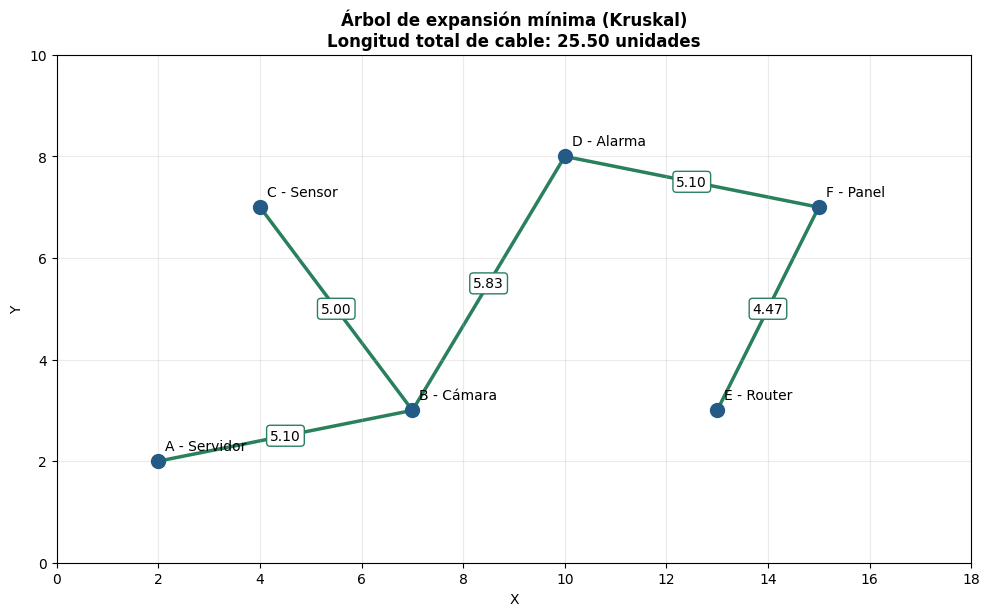

In [6]:
fig, ax = plt.subplots(figsize=(10,6))
for peso,a,b in mst:
    _,x1,y1 = dispositivos[a]
    _,x2,y2 = dispositivos[b]
    ax.plot([x1,x2],[y1,y2],color="#29805c",linewidth=2.5,zorder=1)
    ax.annotate(f"{peso:.2f}",((x1+x2)/2,(y1+y2)/2),ha="center",va="center",bbox=dict(boxstyle="round,pad=0.25",facecolor="white",edgecolor="#29805c"),zorder=4)
graficar_dispositivos(ax)
ax.set_title(f"Árbol de expansión mínima (Kruskal)\nLongitud total de cable: {total:.2f} unidades",weight="bold")
fig.tight_layout()
plt.show()

## Verificación y conclusión

In [7]:
alcanzados = {ids[0]}
while True:
    anteriores = len(alcanzados)
    for _,a,b in mst:
        if a in alcanzados or b in alcanzados:
            alcanzados.update([a,b])
    if len(alcanzados) == anteriores:
        break
assert alcanzados == set(ids)
assert es_max_heap(heap) and heap[0][0] == "T07"
assert len(mst) == 5
print("Verificación: los seis dispositivos están conectados con cinco aristas.")
print(f"Longitud total mínima: {total:.2f} unidades.")
print("La tarea T07 quedó en la raíz del Max-Heap.")

Verificación: los seis dispositivos están conectados con cinco aristas.
Longitud total mínima: 25.50 unidades.
La tarea T07 quedó en la raíz del Max-Heap.


La cola de prioridad permite procesar primero las tareas más urgentes y conserva la propiedad del Max-Heap tras las extracciones y la inserción. Kruskal conecta los seis dispositivos con cinco aristas, sin ciclos, con una longitud mínima de cable de 25.50 unidades.